In [2]:
from google.colab import drive
#drive.mount('/content/drive')

## Unzip Archive and Inspect Data

In [3]:
import zipfile
import os

archive_path = '/content/drive/MyDrive/UG MSC/Deep Learning/End of Sem Project/archive.zip'
extraction_dir = '/content/extracted_archive'

# Create the extraction directory if it doesn't exist
os.makedirs(extraction_dir, exist_ok=True)

try:
    with zipfile.ZipFile(archive_path, 'r') as zip_ref:
        zip_ref.extractall(extraction_dir)
    print(f"Archive '{archive_path}' successfully extracted to '{extraction_dir}'")
except FileNotFoundError:
    print(f"Error: Archive file not found at '{archive_path}'")
except zipfile.BadZipFile:
    print(f"Error: The file at '{archive_path}' is not a valid zip file.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Archive '/content/drive/MyDrive/UG MSC/Deep Learning/End of Sem Project/archive.zip' successfully extracted to '/content/extracted_archive'


In [4]:
import os

# List the contents of the extracted directory
extracted_contents = os.listdir(extraction_dir)
print(f"Contents of '{extraction_dir}':\n{extracted_contents}")

Contents of '/content/extracted_archive':
['10259', '13689', '9382', '10261', '14154', '9177', '9227', '12907', '13617', '12824', '12875', '12752', '12947', '15515', '10291', '8951', '10269', '12817', '12748', '12878', '14191', '12935', '9344', '8980', '10260', '10264', '13693', '9178', '9345', '15510', '9029', '14081', '9323', '12931', '16551', '12951', '12826', '14188', '16570', '8959', '13616', '16568', '13666', '16532', '13400', '15633', '10279', '12895', '9023', '9073', '12871', '9035', '12948', '15903', '10304', '12867', '9043', '10292', '9037', '10282', '9076', '10256', '13459', '15840', '10288', '16531', '12883', '16555', '14211', '12894', '9267', '8914', '14213', '14212', '16166', '9383', '9083', '13019', '12811', '13461', '10301', '9077', '16165', '14156', '9254', '12879', '12882', '15634', '12821', '9174', '15632', '15512', '9256', '13613', '9346', '12750', '12886', '16167', '14306', '13404', '12893', '8956', '9291', '10273', '15472', '10277', '12909', '14321', '9290', '1281

In [5]:
import os

# Path to the IDC_regular_ps50_idx5 directory
idc_data_dir = os.path.join(extraction_dir, 'IDC_regular_ps50_idx5')

# List the contents of this directory
if os.path.exists(idc_data_dir):
    idc_contents = os.listdir(idc_data_dir)
    print(f"Contents of '{idc_data_dir}':\n{idc_contents[:10]}... (showing first 10 items)") # Print first few items to avoid excessive output
    print(f"Total items in '{idc_data_dir}': {len(idc_contents)}")
else:
    print(f"Error: Directory '{idc_data_dir}' not found.")

Contents of '/content/extracted_archive/IDC_regular_ps50_idx5':
['10259', '13689', '9382', '10261', '14154', '9177', '9227', '12907', '13617', '12824']... (showing first 10 items)
Total items in '/content/extracted_archive/IDC_regular_ps50_idx5': 279


In [6]:
import os

# Get the first patient ID from the list (if available)
if idc_contents:
    sample_patient_id = idc_contents[0]
    sample_patient_dir = os.path.join(idc_data_dir, sample_patient_id)

    # List the contents of the sample patient directory
    if os.path.exists(sample_patient_dir):
        patient_dir_contents = os.listdir(sample_patient_dir)
        print(f"Contents of sample patient directory '{sample_patient_dir}':\n{patient_dir_contents}")
    else:
        print(f"Error: Sample patient directory '{sample_patient_dir}' not found.")
else:
    print("No patient directories found in 'IDC_regular_ps50_idx5'.")

Contents of sample patient directory '/content/extracted_archive/IDC_regular_ps50_idx5/10259':
['0', '1']


### Data Loading

In [7]:
import os
import pandas as pd

# 1. Define the base directory where the IDC data is located
base_idc_dir = '/content/extracted_archive/IDC_regular_ps50_idx5'

# 2. Initialize empty lists
image_paths = []
labels = []
patient_ids = []

# 3. Iterate through each patient ID directory
for patient_id_dir in os.listdir(base_idc_dir):
    patient_id_path = os.path.join(base_idc_dir, patient_id_dir)

    # Ensure it's a directory and not IDC_regular_ps50_idx5 (which was also listed)
    if os.path.isdir(patient_id_path) and patient_id_dir != 'IDC_regular_ps50_idx5': # Excluding IDC_regular_ps50_idx5 if it somehow gets listed again
        # 4. Inside each patient directory, iterate through the subdirectories named '0' and '1'
        for label_dir in ['0', '1']:
            label_path = os.path.join(patient_id_path, label_dir)

            if os.path.isdir(label_path):
                # 5. For each image file, construct its full path, determine its label, and record the patient ID
                for image_filename in os.listdir(label_path):
                    if image_filename.endswith('.png'): # Assuming image files are .png
                        full_image_path = os.path.join(label_path, image_filename)
                        current_label = int(label_dir) # '0' or '1'

                        # 6. Append the image path, label, and patient ID to their respective lists
                        image_paths.append(full_image_path)
                        labels.append(current_label)
                        patient_ids.append(patient_id_dir)

print(f"Collected {len(image_paths)} image paths.")
print(f"Number of labels: {len(labels)}")
print(f"Number of patient IDs: {len(patient_ids)}")

Collected 277524 image paths.
Number of labels: 277524
Number of patient IDs: 277524


In [8]:
# Create a pandas DataFrame from the collected lists and display its head and info.
df_images = pd.DataFrame({
    'image_path': image_paths,
    'label': labels,
    'patient_id': patient_ids
})

print("First 5 rows of the DataFrame:")
print(df_images.head())
print("\nDataFrame Info:")
df_images.info()

First 5 rows of the DataFrame:
                                          image_path  label patient_id
0  /content/extracted_archive/IDC_regular_ps50_id...      0      10259
1  /content/extracted_archive/IDC_regular_ps50_id...      0      10259
2  /content/extracted_archive/IDC_regular_ps50_id...      0      10259
3  /content/extracted_archive/IDC_regular_ps50_id...      0      10259
4  /content/extracted_archive/IDC_regular_ps50_id...      0      10259

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 277524 entries, 0 to 277523
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   image_path  277524 non-null  object
 1   label       277524 non-null  int64 
 2   patient_id  277524 non-null  object
dtypes: int64(1), object(2)
memory usage: 6.4+ MB


In [9]:
print("Value counts for the 'label' column:")
print(df_images['label'].value_counts())
print("\nPercentage of each label:")
print(df_images['label'].value_counts(normalize=True) * 100)

Value counts for the 'label' column:
label
0    198738
1     78786
Name: count, dtype: int64

Percentage of each label:
label
0    71.611104
1    28.388896
Name: proportion, dtype: float64


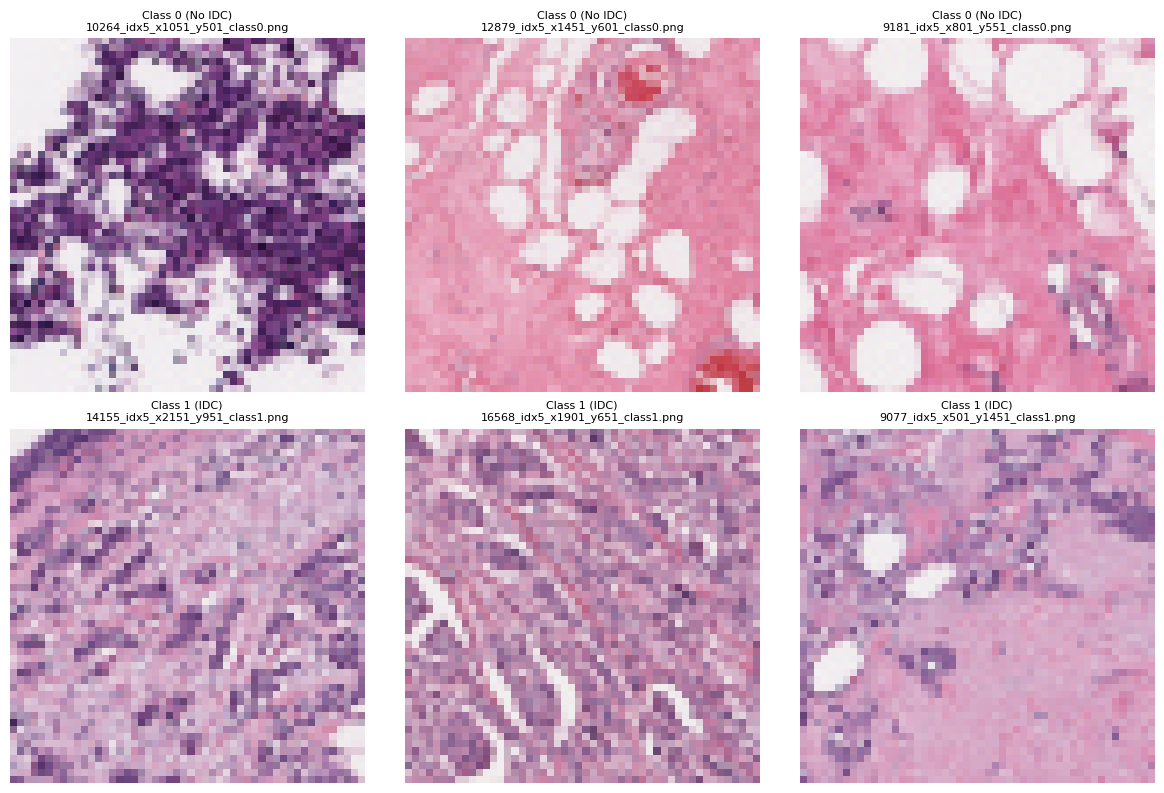

In [10]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

# Randomly select 3 images from class 0 and 3 from class 1
sample_0 = df_images[df_images['label'] == 0]['image_path'].sample(3, random_state=42).tolist()
sample_1 = df_images[df_images['label'] == 1]['image_path'].sample(3, random_state=42).tolist()

# Create a 2x3 subplot
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Plot images for class 0
for i, img_path in enumerate(sample_0):
    img = mpimg.imread(img_path)
    axes[0, i].imshow(img)
    axes[0, i].set_title(f'Class 0 (No IDC)\n{img_path.split("/")[-1]}', fontsize=8)
    axes[0, i].axis('off')

# Plot images for class 1
for i, img_path in enumerate(sample_1):
    img = mpimg.imread(img_path)
    axes[1, i].imshow(img)
    axes[1, i].set_title(f'Class 1 (IDC)\n{img_path.split("/")[-1]}', fontsize=8)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

## Build Neural Network Model

In [11]:
from sklearn.model_selection import train_test_split

# Get unique patient IDs
unique_patient_ids = df_images['patient_id'].unique()

# Perform a patient-stratified split on the patient IDs
# To stratify patient IDs, we need a stratification key. For now, let's use a dummy array if direct stratification by a target label for patients is complex.
# A common practice is to create a 'patient_label' if a patient has a dominant label, or simply split patient IDs randomly.
# However, the proposal mentions 'patient-stratified splits to prevent leakage', implying a split where patient data is kept together.
# For stratification by labels, we might need to compute a label for each patient (e.g., if a patient has IDC-positive patches, consider them 'positive').

# Let's create a patient-level label for stratification: if a patient has at least one '1' label, assign '1', otherwise '0'.
patient_labels = df_images.groupby('patient_id')['label'].max().reset_index()
patient_id_train, patient_id_val, _, _ = train_test_split(
    patient_labels['patient_id'], patient_labels['label'],
    test_size=0.2, random_state=42, stratify=patient_labels['label']
)

# Create training and validation DataFrames
train_df = df_images[df_images['patient_id'].isin(patient_id_train)].reset_index(drop=True)
val_df = df_images[df_images['patient_id'].isin(patient_id_val)].reset_index(drop=True)

print(f"Shape of training DataFrame: {train_df.shape}")
print(f"Shape of validation DataFrame: {val_df.shape}")

print("Train label distribution:")
print(train_df['label'].value_counts(normalize=True))

print("Validation label distribution:")
print(val_df['label'].value_counts(normalize=True))

Shape of training DataFrame: (217034, 3)
Shape of validation DataFrame: (60490, 3)
Train label distribution:
label
0    0.71393
1    0.28607
Name: proportion, dtype: float64
Validation label distribution:
label
0    0.723938
1    0.276062
Name: proportion, dtype: float64


In [12]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image dimensions as specified in the proposal
IMG_WIDTH = 224
IMG_HEIGHT = 224
BATCH_SIZE = 32 # A common batch size for training

# Data Augmentation and Preprocessing
# The proposal mentions "stain normalisation, augmentation, resizing to 224 ×224"
# Stain normalization is complex and often done as a separate step or with specialized libraries.
# For now, we'll focus on resizing and common augmentations. Rescaling images to [0, 1] is standard.

train_datagen = ImageDataGenerator(
    rescale=1./255, # Rescale pixel values to [0, 1]
    rotation_range=20, # Random rotation up to 20 degrees
    width_shift_range=0.2, # Random horizontal shift
    height_shift_range=0.2, # Random vertical shift
    shear_range=0.2, # Shear transformations
    zoom_range=0.2, # Random zoom
    horizontal_flip=True, # Random horizontal flip
    vertical_flip=True, # Random vertical flip
    fill_mode='nearest' # Strategy for filling in new pixels
)

val_datagen = ImageDataGenerator(
    rescale=1./255 # Only rescale for validation, no augmentation
)

# Convert the 'label' column to string type for flow_from_dataframe with class_mode='binary'
train_df['label'] = train_df['label'].astype(str)
val_df['label'] = val_df['label'].astype(str)

# Create data generators from DataFrames
# The `class_mode` is 'binary' because we have two classes (0 or 1).
# `target_size` is the desired image dimensions.
# `color_mode` is 'rgb' for color images.

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='label',
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=True,
    seed=42
)

validation_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='label',
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False, # No need to shuffle validation data
    seed=42
)

print("Train and validation data generators created.")

Found 217034 validated image filenames belonging to 2 classes.
Found 60490 validated image filenames belonging to 2 classes.
Train and validation data generators created.


In [29]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Define Focal Loss as mentioned in the proposal
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1. - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred) - (1. - y_true) * tf.math.log(1. - y_pred)
        loss = alpha * tf.math.pow(1 - y_pred, gamma) * cross_entropy
        return tf.reduce_mean(loss, axis=-1)
    return focal_loss_fixed

# Explicitly set the device to CPU to avoid potential GPU issues during model loading
with tf.device('/CPU:0'):
    # Load the pre-trained EfficientNetB0 model without the top (classification) layer
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(IMG_WIDTH, IMG_HEIGHT, 3))

    # Freeze the base model layers to prevent their weights from being updated during training
    for layer in base_model.layers:
        layer.trainable = False

    # Add custom classification head
    x = base_model.output
    x = GlobalAveragePooling2D()(x) # Global Average Pooling to reduce dimensions
    x = Dense(128, activation='relu')(x) # A dense layer with ReLU activation
    predictions = Dense(1, activation='sigmoid')(x) # Output layer for binary classification with sigmoid activation

    # Create the full model
    model = Model(inputs=base_model.input, outputs=predictions)

    print("Model architecture defined using EfficientNetB0.")
    model.summary()


    # Compile the model
    # Using Adam optimizer, Focal Loss, and specified metrics
    model.compile(
        optimizer=Adam(learning_rate=0.0001), # A common starting learning rate
        loss=focal_loss(),
        metrics=[
            'accuracy',
            tf.keras.metrics.Precision(),
            tf.keras.metrics.Recall(),
            tf.keras.metrics.AUC(name='auc_roc'),
            tf.keras.metrics.AUC(name='auc_pr', curve='PR')
        ]
    )

    print("Model compiled successfully.")

    EPOCHS = 10 # Define the number of training epochs

    # Train the model
    history = model.fit(
        train_generator,
        epochs=EPOCHS,
        validation_data=validation_generator,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=0.00001)
        ]
    )

print("Model training complete.")

Model architecture defined using EfficientNetB0.


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_12        │ (None, 224, 224,  │          0 │ input_layer_6[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_6     │ (None, 224, 224,  │          7 │ rescaling_12[0][… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_13        │ (None, 224, 224,  │          0 │ normalization_6[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_13[0][… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Model compiled successfully.
Epoch 1/10
6783/6783 ━━━━━━━━━━━━━━━━━━━━ 2621s 386ms/step - accuracy: 0.2861 - auc_pr: 0.2862 - auc_roc: 0.5004 - loss: 4.2142e-05 - precision_1: 0.2861 - recall_1: 1.0000 - val_accuracy: 0.2761 - val_auc_pr: 0.2761 - val_auc_roc: 0.5000 - val_loss: 2.4579e-10 - val_precision_1: 0.2761 - val_recall_1: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/10
6783/6783 ━━━━━━━━━━━━━━━━━━━━ 2613s 385ms/step - accuracy: 0.2861 - auc_pr: 0.2861 - auc_roc: 0.5000 - loss: 8.2943e-09 - precision_1: 0.2861 - recall_1: 1.0000 - val_accuracy: 0.2761 - val_auc_pr: 0.2761 - val_auc_roc: 0.5000 - val_loss: 4.2633e-12 - val_precision_1: 0.2761 - val_recall_1: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/10
6783/6783 ━━━━━━━━━━━━━━━━━━━━ 2613s 385ms/step - accuracy: 0.2861 - auc_pr: 0.2861 - auc_roc: 0.5000 - loss: 1.4892e-09 - precision_1: 0.2861 - recall_1: 1.0000 - val_accuracy: 0.2761 - val_auc_pr: 0.2761 - val_auc_roc: 0.5000 - val_loss: 3.4360e-13 - val_precision_1: 0.2761 - val

## Plotting the training history (loss and metrics)

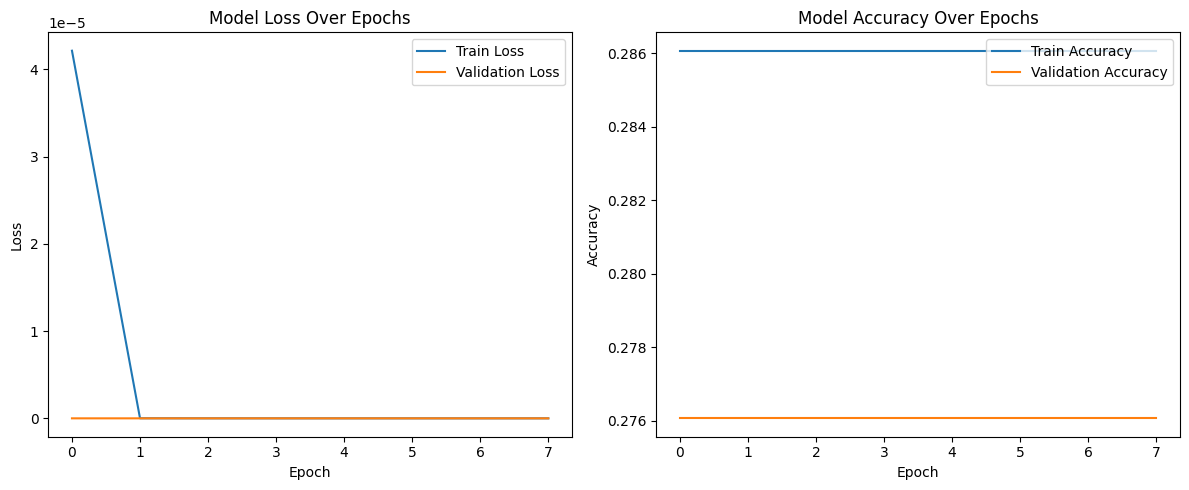

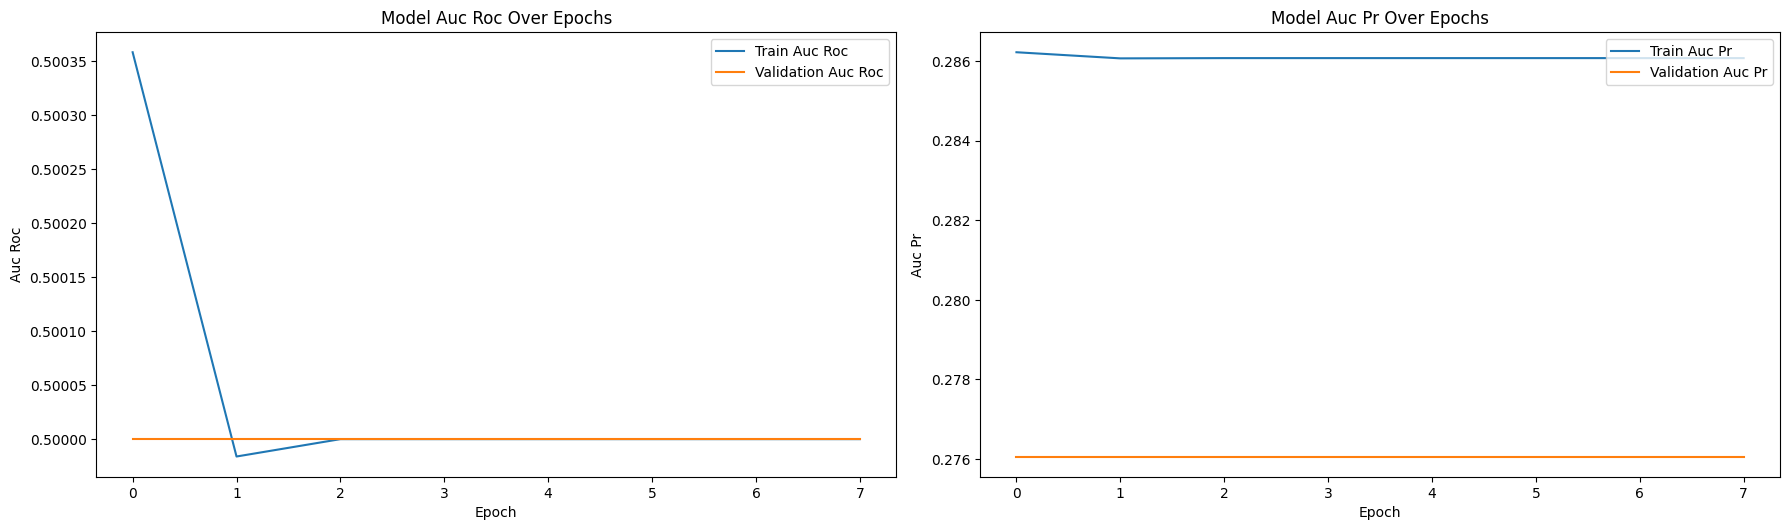

Training history plots generated.


In [30]:
import matplotlib.pyplot as plt

# Get the training history data
hist = history.history

# Plot training & validation loss values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(hist['loss'], label='Train Loss')
plt.plot(hist['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper right')

# Plot training & validation accuracy values
plt.subplot(1, 2, 2)
plt.plot(hist['accuracy'], label='Train Accuracy')
plt.plot(hist['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Plot additional metrics if available
metrics = ['precision', 'recall', 'auc_roc', 'auc_pr']

plt.figure(figsize=(18, 10))
for i, metric in enumerate(metrics):
    if metric in hist and f'val_{metric}' in hist:
        plt.subplot(2, 2, i + 1)
        plt.plot(hist[metric], label=f'Train {metric.replace("_", " ").title()}')
        plt.plot(hist[f'val_{metric}'], label=f'Validation {metric.replace("_", " ").title()}')
        plt.title(f'Model {metric.replace("_", " ").title()} Over Epochs')
        plt.ylabel(metric.replace("_", " ").title())
        plt.xlabel('Epoch')
        plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print("Training history plots generated.")

In [19]:
# NOTE: Since staintools installation fails in this environment, this code serves as a template.
# To run this in a compatible environment, uncomment the code below.

'''
import staintools
import matplotlib.pyplot as plt

# 1. Select a target image to serve as the color reference
target_image_path = train_df['image_path'].iloc[0]
target_image = staintools.read_image(target_image_path)

# Standardize luminosity of the target image
target_image = staintools.LuminosityStandardizer.standardize(target_image)

# 2. Initialize and fit the Macenko Normalizer
normalizer = staintools.MacenkoNormalizer()
normalizer.fit(target_image)

def normalize_image(img_path):
    """Reads an image, standardizes luminosity, and applies Macenko normalization."""
    img = staintools.read_image(img_path)
    img = staintools.LuminosityStandardizer.standardize(img)
    # Transform the image to match the target stain profile
    normalized_img = normalizer.transform(img)
    return img, normalized_img

# 3. Visualize the transformation on a sample image
sample_path = train_df['image_path'].iloc[15]
original_img, normalized_img = normalize_image(sample_path)

# Plot the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(target_image)
axes[0].set_title("Reference Target Image")
axes[0].axis('off')

axes[1].imshow(original_img)
axes[1].set_title("Original Source Image")
axes[1].axis('off')

axes[2].imshow(normalized_img)
axes[2].set_title("Macenko Normalized Image")
axes[2].axis('off')

plt.tight_layout()
plt.show()
'''
print("Stain normalization code template defined.")

Stain normalization code template defined.


## Baseline CNN

Defining a standard Convolutional Neural Network as a baseline for comparison against EfficientNetB0 and ViT.

In [12]:
# NOTE: This code is a template for the Baseline CNN.
# Uncomment to run the training when ready.

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Define Focal Loss as mentioned in the proposal
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1. - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred) - (1. - y_true) * tf.math.log(1. - y_pred)
        loss = alpha * tf.math.pow(1 - y_pred, gamma) * cross_entropy
        return tf.reduce_mean(loss, axis=-1)
    return focal_loss_fixed

# Define Baseline CNN architecture
with tf.device('/GPU:0'):
    cnn_model = Sequential([
        tf.keras.layers.Input(shape=(224, 224, 3)),
        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])

    cnn_model.compile(
        optimizer='adam',
        loss=focal_loss(), # Using the focal_loss defined earlier
        metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
    )

# Template for training and saving weights:
cnn_history = cnn_model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator
)
cnn_model.save_weights('baseline_cnn_weights.h5')
print("Baseline CNN weights saved.")
# print("Baseline CNN architecture template defined.")

Epoch 1/10
6783/6783 ━━━━━━━━━━━━━━━━━━━━ 2301s 338ms/step - accuracy: 0.2861 - loss: 6.2514e-06 - precision: 0.2861 - recall: 1.0000 - val_accuracy: 0.2761 - val_loss: 4.1004e-14 - val_precision: 0.2761 - val_recall: 1.0000
Epoch 2/10
6783/6783 ━━━━━━━━━━━━━━━━━━━━ 2265s 334ms/step - accuracy: 0.2861 - loss: 4.0436e-14 - precision: 0.2861 - recall: 1.0000 - val_accuracy: 0.2761 - val_loss: 4.1004e-14 - val_precision: 0.2761 - val_recall: 1.0000
Epoch 3/10
6783/6783 ━━━━━━━━━━━━━━━━━━━━ 2269s 335ms/step - accuracy: 0.2861 - loss: 4.0435e-14 - precision: 0.2861 - recall: 1.0000 - val_accuracy: 0.2761 - val_loss: 4.1004e-14 - val_precision: 0.2761 - val_recall: 1.0000
Epoch 4/10
6783/6783 ━━━━━━━━━━━━━━━━━━━━ 2263s 334ms/step - accuracy: 0.2861 - loss: 4.0435e-14 - precision: 0.2861 - recall: 1.0000 - val_accuracy: 0.2761 - val_loss: 4.1004e-14 - val_precision: 0.2761 - val_recall: 1.0000
Epoch 5/10
6783/6783 ━━━━━━━━━━━━━━━━━━━━ 2264s 334ms/step - accuracy: 0.2861 - loss: 4.0435e-14 - p

ValueError: The filename must end in `.weights.h5`. Received: filepath=baseline_cnn_weights.h5

In [13]:
cnn_model.save_weights('baseline_cnn_weights.weights.h5')

## Data Balancing (Undersampling)
Balancing the dataset before building the Vision Transformer by undersampling class 0 to match the count of class 1.

In [13]:
import pandas as pd

# Separate the classes
df_class_1 = df_images[df_images['label'] == 1]
df_class_0 = df_images[df_images['label'] == 0]

# Undersample class 0 to match the number of samples in class 1
df_class_0_under = df_class_0.sample(len(df_class_1), random_state=42)

# Combine and shuffle to create the balanced dataset
df_balanced = pd.concat([df_class_0_under, df_class_1], axis=0).sample(frac=1, random_state=42).reset_index(drop=True)

print("New value counts for the 'label' column after undersampling:")
print(df_balanced['label'].value_counts())

New value counts for the 'label' column after undersampling:
label
0    78786
1    78786
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split

# Re-perform the patient-stratified split on the new balanced dataset
patient_labels_bal = df_balanced.groupby('patient_id')['label'].max().reset_index()
patient_id_train_bal, patient_id_val_bal = train_test_split(
    patient_labels_bal['patient_id'],
    test_size=0.2,
    random_state=42,
    stratify=patient_labels_bal['label']
)

# Create the new balanced training and validation DataFrames
train_df_bal = df_balanced[df_balanced['patient_id'].isin(patient_id_train_bal)].reset_index(drop=True)
val_df_bal = df_balanced[df_balanced['patient_id'].isin(patient_id_val_bal)].reset_index(drop=True)

# Convert labels to string for the ImageDataGenerator
train_df_bal['label'] = train_df_bal['label'].astype(str)
val_df_bal['label'] = val_df_bal['label'].astype(str)

print(f"Balanced train shape: {train_df_bal.shape}")
print(f"Balanced validation shape: {val_df_bal.shape}")

# Recreate data generators with the balanced data
train_generator_bal = train_datagen.flow_from_dataframe(
    dataframe=train_df_bal,
    x_col='image_path',
    y_col='label',
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=True,
    seed=42
)

validation_generator_bal = val_datagen.flow_from_dataframe(
    dataframe=val_df_bal,
    x_col='image_path',
    y_col='label',
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False,
    seed=42
)

print("Balanced data generators ready.")

Balanced train shape: (123396, 3)
Balanced validation shape: (34176, 3)
Found 123396 validated image filenames belonging to 2 classes.
Found 34176 validated image filenames belonging to 2 classes.
Balanced data generators ready.


## Vision Transformer (ViT)

In [15]:
# !pip install transformers torch evaluate scikit-learn

from transformers import ViTForImageClassification, ViTImageProcessor, TrainingArguments, Trainer
import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Define model and feature extractor
model_name = 'google/vit-base-patch16-224-in21k'
feature_extractor = ViTImageProcessor.from_pretrained(model_name)

vit_model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=2,
    ignore_mismatched_sizes=True
)

# 1. Create a PyTorch Dataset for Hugging Face Trainer
class IDCHFDataset(Dataset):
    def __init__(self, df, processor):
        self.df = df.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'image_path']
        label = int(self.df.loc[idx, 'label'])
        image = Image.open(img_path).convert("RGB")

        # Preprocess the image for ViT
        encoding = self.processor(images=image, return_tensors="pt")
        pixel_values = encoding['pixel_values'].squeeze() # Remove batch dimension

        return {"pixel_values": pixel_values, "labels": torch.tensor(label, dtype=torch.long)}

# Create dataset instances using the balanced dataframes defined earlier
train_dataset = IDCHFDataset(train_df_bal, feature_extractor)
val_dataset = IDCHFDataset(val_df_bal, feature_extractor)

# 2. Define evaluation metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average='binary', zero_division=0)
    acc = accuracy_score(labels, predictions)
    return {'accuracy': acc, 'f1': f1, 'precision': precision, 'recall': recall}

# 3. Setup Training Arguments
training_args = TrainingArguments(
    output_dir='./vit_breast_cancer_results',
    per_device_train_batch_size=16, # Decrease to 8 if you face OOM errors
    per_device_eval_batch_size=16,
    eval_strategy="epoch", # Evaluate at the end of each epoch
    save_strategy="epoch",
    num_train_epochs=10, # Adjust based on requirement
    fp16=torch.cuda.is_available(), # Enable mixed precision to save GPU memory
    logging_steps=50,
    load_best_model_at_end=True,
)

# 4. Initialize Trainer
trainer = Trainer(
    model=vit_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

print("Trainer initialized. Ready to start training.")

# 5. Start Training (Uncomment the line below to train)
trainer.train()

# 6. Save the final model
vit_model.save_pretrained('./vit_breast_cancer_weights')
# feature_extractor.save_pretrained('./vit_breast_cancer_weights')
print("ViT weights saved.")

Loading weights:   0%|          | 0/6 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
encoder.layer.{0...11}.attention.attention.value.bias   | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_before.bias            | UNEXPECTED | 
encoder.layer.{0...11}.output.dense.bias                | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.key.bias     | UNEXPECTED | 
encoder.layer.{0...11}.attention.output.dense.weight    | UNEXPECTED | 
encoder.layer.{0...11}.layernorm_after.weight           | UNEXPECTED | 
encoder.layer.{0...11}.output.dense.weight              | UNEXPECTED | 
encoder.layer.{0...11}.attention.output.dense.bias      | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.query.weight | UNEXPECTED | 
encoder.layer.{0...11}.attention.attention.value.weight | UNEXPECTED | 
encoder.layer.{0...11}.intermediate.dense.w

Trainer initialized. Ready to start training.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.333813,0.403073,0.834972,0.835597,0.814051,0.858315
2,0.314746,0.384400,0.843165,0.845649,0.814500,0.879274
3,0.339913,0.375226,0.841555,0.835255,0.848918,0.822025
4,0.326283,0.367921,0.841643,0.835721,0.847399,0.824361
5,0.294364,0.373319,0.846559,0.845837,0.830744,0.861489
6,0.239332,0.399238,0.840151,0.833450,0.848901,0.818552
7,0.246554,0.405066,0.845623,0.846351,0.823800,0.870172
8,0.254748,0.414340,0.842960,0.839143,0.839974,0.838314
9,0.197441,0.435691,0.843194,0.843171,0.824519,0.862686
10,0.210986,0.470836,0.837049,0.832021,0.838216,0.825918


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

ViT weights saved.


## Model Evaluation

Evaluating Vision Transformer (trainer)...


F1 Score: 0.8357
Balanced Accuracy: 0.8413


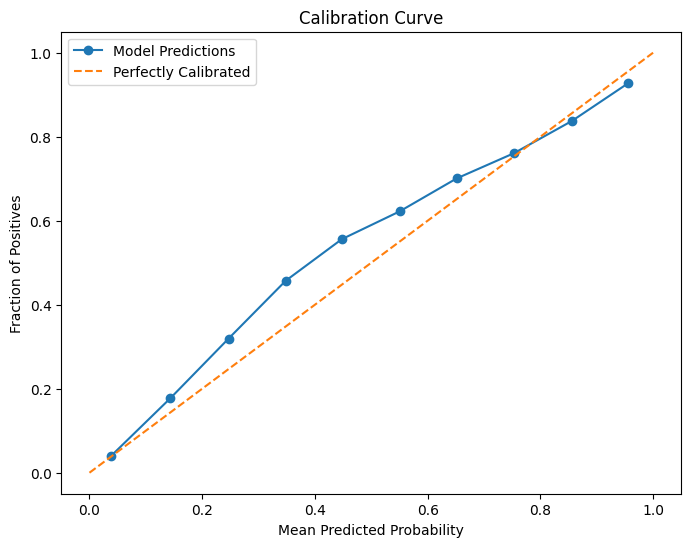

Evaluation metrics calculated.


In [18]:
from sklearn.metrics import f1_score, balanced_accuracy_score
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import numpy as np
import torch

# Determine which model is available in the current session
if 'model' in locals():
    print("Evaluating EfficientNetB0 (model)...")
    y_pred_prob = model.predict(validation_generator).flatten()
    y_true = validation_generator.classes
elif 'cnn_model' in locals():
    print("Evaluating Baseline CNN (cnn_model)...")
    y_pred_prob = cnn_model.predict(validation_generator).flatten()
    y_true = validation_generator.classes
elif 'trainer' in locals():
    print("Evaluating Vision Transformer (trainer)...")
    predictions = trainer.predict(val_dataset)
    logits = predictions.predictions
    # Softmax to get probabilities for class 1
    y_pred_prob = torch.nn.functional.softmax(torch.tensor(logits), dim=-1).numpy()[:, 1]
    y_true = predictions.label_ids
else:
    raise NameError("No trained model (model, cnn_model, or trainer) found in the current session.")

y_pred = (y_pred_prob > 0.5).astype(int)

f1 = f1_score(y_true, y_pred)
bal_acc = balanced_accuracy_score(y_true, y_pred)
print(f"F1 Score: {f1:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")

# Calibration Curve
prob_true, prob_pred = calibration_curve(y_true, y_pred_prob, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Model Predictions')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve')
plt.legend()
plt.show()

print("Evaluation metrics calculated.")

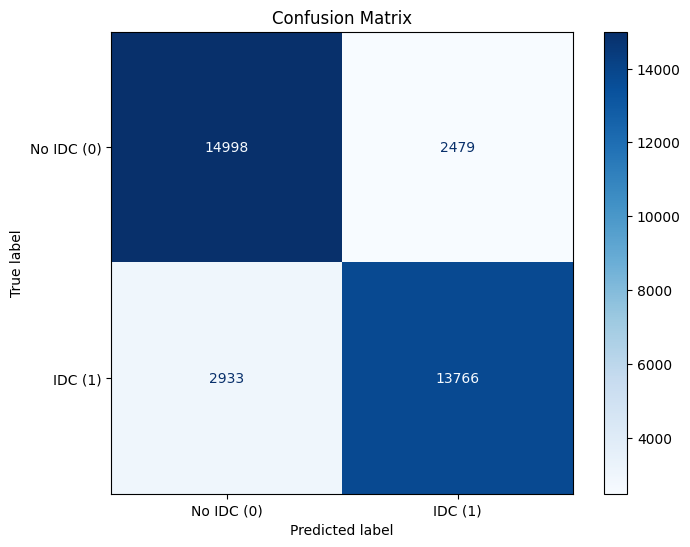

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No IDC (0)', 'IDC (1)'])
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix')
plt.show()